# VRDet: Stage 04b: The Model Zoo (all 22 classifiers)

Every real-time classifier in the project, trained and tested in one place. All models:

* see the same 56 causal inputs (features, lags, HMM filtered probabilities), built by `vrdet.live.model_frame`,
  the function the live app uses
* predict the same target: the HMM hindsight labels (notebook 04)
* use the same decision rule: Chaotic when P(Chaotic) ≥ τ, τ tuned on the last training year (`TunedChaoticThreshold`)

Part A trains every model on 2017–2024 and tests on 2025–2026 (a single split you can re-run here). Part B shows the
full walk-forward evaluation 2022–2026 from `scripts/train_zoo.py`, with block-bootstrap confidence intervals.
The model definitions live in `src/vrdet/zoo.py` (sequence networks in `seqnet.py`).

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = REPO / 'data' / 'processed'      # raw data: <repo>/data/raw (or set VRDET_DATA)
FIG = OUT / 'figures'

sys.path.insert(0, str(REPO / 'src'))
for m in [m for m in sys.modules if m == 'vrdet' or m.startswith('vrdet.')]:
    del sys.modules[m]  # forget any previously imported (stale) vrdet
FIG.mkdir(parents=True, exist_ok=True)
print('repo:', REPO)

repo: C:\dev\vrdet


In [2]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, f1_score

from vrdet.classifiers import TunedChaoticThreshold
from vrdet.data import load_raw
from vrdet.evaluate import regime_episodes_count, regime_metrics
from vrdet.labels import STATE_NAMES, HMMLabeler
from vrdet.live import MODEL_DIR, classify, model_frame
from vrdet.zoo import CONTEXT, MAKERS, MODELS

pd.set_option('display.width', 220)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True, 'font.size': 9.5})
REGIME_COLORS = ['#2e9e5b', '#d9a400', '#d93636']      # Quiet, Normal, Chaotic (same as the dashboard)
HIGHLIGHT = {'production': '#2a78d6', 'benchmark': '#eb6834'}   # categorical slots 1-2
GREY = '#9aa3ad'

TRAIN_START, TEST_START = '2017-01-01', '2025-01-01'
PRODUCTION, BENCHMARK = 'lightgbm', 'hmm_filter'
SKIP = set()   # e.g. {'transformer', 'adaboost', 'tcn'} for a quick run (they take minutes each)

## 1. Inputs and labels

In [3]:
hmm = HMMLabeler.from_json((MODEL_DIR / 'hmm_labeler.json').read_text())
X = model_frame(load_raw(), hmm)
y = hmm.hindsight(X)
y = y[y.index >= pd.Timestamp(TRAIN_START, tz=y.index.tz)]
X = X.loc[y.index]
test = X.index >= pd.Timestamp(TEST_START, tz=X.index.tz)
train = ~test
y_test = y[test]
print(f'{X.shape[1]} inputs | train {train.sum():,} bars ({X.index[train][0]:%Y-%m-%d} -> {X.index[train][-1]:%Y-%m-%d}), '
      f'{regime_episodes_count(y[train])} Chaotic episodes | test {test.sum():,} bars '
      f'({X.index[test][0]:%Y-%m-%d} -> {X.index[test][-1]:%Y-%m-%d}), {regime_episodes_count(y_test)} episodes')
pd.DataFrame({'train': y[train].value_counts(normalize=True), 'test': y_test.value_counts(normalize=True)}).rename(
    index=dict(enumerate(STATE_NAMES))).round(3)

56 inputs | train 49,100 bars (2017-01-02 -> 2024-12-31), 226 Chaotic episodes | test 11,201 bars (2025-01-01 -> 2026-10-29), 45 episodes


,train,test
regime,,
Quiet,0.498,0.58
Normal,0.418,0.38
Chaotic,0.084,0.04


## 2. The models

In [4]:
catalogue = pd.DataFrame(MODELS, index=['name', 'family', 'description']).T
catalogue.index.name = 'key'
catalogue.sort_values('family')

,name,family,description
key,,,
random_forest,Random Forest,Bagging,"300 deep-ish trees on bootstrap samples, class..."
extra_trees,Extra Trees,Bagging,Like Random Forest but with random split point...
adaboost,AdaBoost,Boosting,"100 shallow trees, each focusing on the bars t..."
lda,LDA,Discriminant analysis,Linear discriminant analysis with shrinkage: o...
qda,QDA,Discriminant analysis,Quadratic discriminant analysis: one covarianc...
soft_vote,Soft voting,Ensemble,"Average of LightGBM, XGBoost and Random Forest..."
stacking,Stacking,Ensemble,"Logistic meta-model on LightGBM, XGBoost and l..."
lightgbm,LightGBM + HMM,Gradient boosting,Production model. Leaf-wise boosted trees; han...
xgboost,XGBoost,Gradient boosting,Depth-wise boosted trees with second-order gra...


# Part A: train and test every model (2017–2024 → 2025–2026)

For each model: fit on 2017–2023 and tune τ on 2024, refit on 2017–2024, then predict 2025–2026. Sequence models get
the 32 bars before the test period as context. The full loop takes about 25 minutes on 8 CPU threads; Transformer,
AdaBoost and the temporal CNN take most of it.

In [5]:
rows = test.nonzero()[0]
ctx = X.iloc[rows[0] - CONTEXT:]
results, probas = {}, {}

p_hmm = X.loc[test, ['p_hmm_Quiet', 'p_hmm_Normal', 'p_hmm_Chaotic']].to_numpy()
results[BENCHMARK] = {'model': 'HMM filter (benchmark)', 'family': 'Benchmark',
                      **regime_metrics(y_test, pd.Series(p_hmm.argmax(1), index=y_test.index)),
                      'pr_auc_chaotic': average_precision_score(y_test == 2, p_hmm[:, 2]), 'tau': np.nan, 'fit_seconds': 0.0}
probas[BENCHMARK] = pd.Series(p_hmm[:, 2], index=y_test.index)

for key, (name, family, _) in MODELS.items():
    if key in SKIP:
        continue
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m = TunedChaoticThreshold(MAKERS[key]).fit(X[train], y[train])
        p = m.predict_proba(ctx)[-len(rows):]
    seconds = time.perf_counter() - t0
    pred = pd.Series(classify(p, m.tau_), index=y_test.index)
    r = regime_metrics(y_test, pred)
    results[key] = {'model': name, 'family': family, **r,
                    'pr_auc_chaotic': average_precision_score(y_test == 2, p[:, 2]), 'tau': m.tau_, 'fit_seconds': seconds}
    probas[key] = pd.Series(p[:, 2], index=y_test.index)
    print(f'{name:<24} macro-F1 {r["macro_f1"]:.3f} | Chaotic P/R {r["chaotic_precision"]:.2f}/{r["chaotic_recall"]:.2f} '
          f'| false alarms/wk {r["false_alarms_per_week"]:.2f} | tau {m.tau_:.2f} | {seconds:.0f}s')

holdout = pd.DataFrame(results).T
holdout.to_csv(OUT / 'zoo_holdout_2025.csv')
pd.DataFrame(probas).to_parquet(OUT / 'zoo_holdout_2025_pchaotic.parquet')

LightGBM + HMM           macro-F1 0.817 | Chaotic P/R 0.61/0.81 | false alarms/wk 0.83 | tau 0.15 | 6s


Logistic regression      macro-F1 0.829 | Chaotic P/R 0.70/0.74 | false alarms/wk 0.54 | tau 0.35 | 3s


Random Forest            macro-F1 0.819 | Chaotic P/R 0.63/0.76 | false alarms/wk 0.72 | tau 0.60 | 18s


Extra Trees              macro-F1 0.814 | Chaotic P/R 0.60/0.79 | false alarms/wk 0.97 | tau 0.60 | 6s


AdaBoost                 macro-F1 0.764 | Chaotic P/R 0.46/0.83 | false alarms/wk 1.42 | tau 0.35 | 141s


...

LDA                      macro-F1 0.806 | Chaotic P/R 0.61/0.79 | false alarms/wk 1.14 | tau 0.60 | 1s


QDA                      macro-F1 0.749 | Chaotic P/R 0.50/0.70 | false alarms/wk 0.94 | tau 0.35 | 1s


SVM (RBF)                macro-F1 0.821 | Chaotic P/R 0.63/0.79 | false alarms/wk 0.71 | tau 0.35 | 26s


Temporal CNN             macro-F1 0.809 | Chaotic P/R 0.59/0.79 | false alarms/wk 0.79 | tau 0.20 | 65s


Ordinal LightGBM         macro-F1 0.816 | Chaotic P/R 0.61/0.81 | false alarms/wk 0.76 | tau 0.15 | 5s


## 3. Results on 2025–2026

In [6]:
cols = ['model', 'family', 'macro_f1', 'chaotic_precision', 'chaotic_recall', 'pr_auc_chaotic', 'episode_recall',
        'false_alarms_per_week', 'tau', 'fit_seconds']
table = holdout[cols].sort_values('macro_f1', ascending=False)
table.style.format({c: '{:.3f}' for c in cols[2:7]} | {'false_alarms_per_week': '{:.2f}', 'tau': '{:.2f}', 'fit_seconds': '{:.0f}'})

,model,family,macro_f1,chaotic_precision,chaotic_recall,pr_auc_chaotic,episode_recall,false_alarms_per_week,tau,fit_seconds
logistic,Logistic regression,Linear,0.829,0.696,0.741,0.789,0.978,0.54,0.35,3
xgboost,XGBoost,Gradient boosting,0.827,0.658,0.786,0.822,1.000,0.72,0.25,11
soft_vote,Soft voting,Ensemble,0.826,0.674,0.743,0.821,1.000,0.60,0.40,39
catboost,CatBoost,Gradient boosting,0.822,0.669,0.734,0.811,1.000,0.61,0.30,30
transformer,Transformer,Sequence model,0.822,0.702,0.703,0.765,0.978,0.62,0.40,186
svm,SVM (RBF),Kernel method,0.821,0.628,0.788,0.759,1.000,0.71,0.35,26
random_forest,Random Forest,Bagging,0.819,0.631,0.761,0.815,1.000,0.72,0.60,18
hist_gb,Hist. gradient boosting,Gradient boosting,0.818,0.618,0.792,0.803,1.000,0.79,0.15,13
lightgbm,LightGBM + HMM,Gradient boosting,0.817,0.606,0.808,0.810,1.000,0.83,0.15,6
ordinal,Ordinal LightGBM,Ordinal,0.816,0.609,0.808,0.808,1.000,0.76,0.15,5


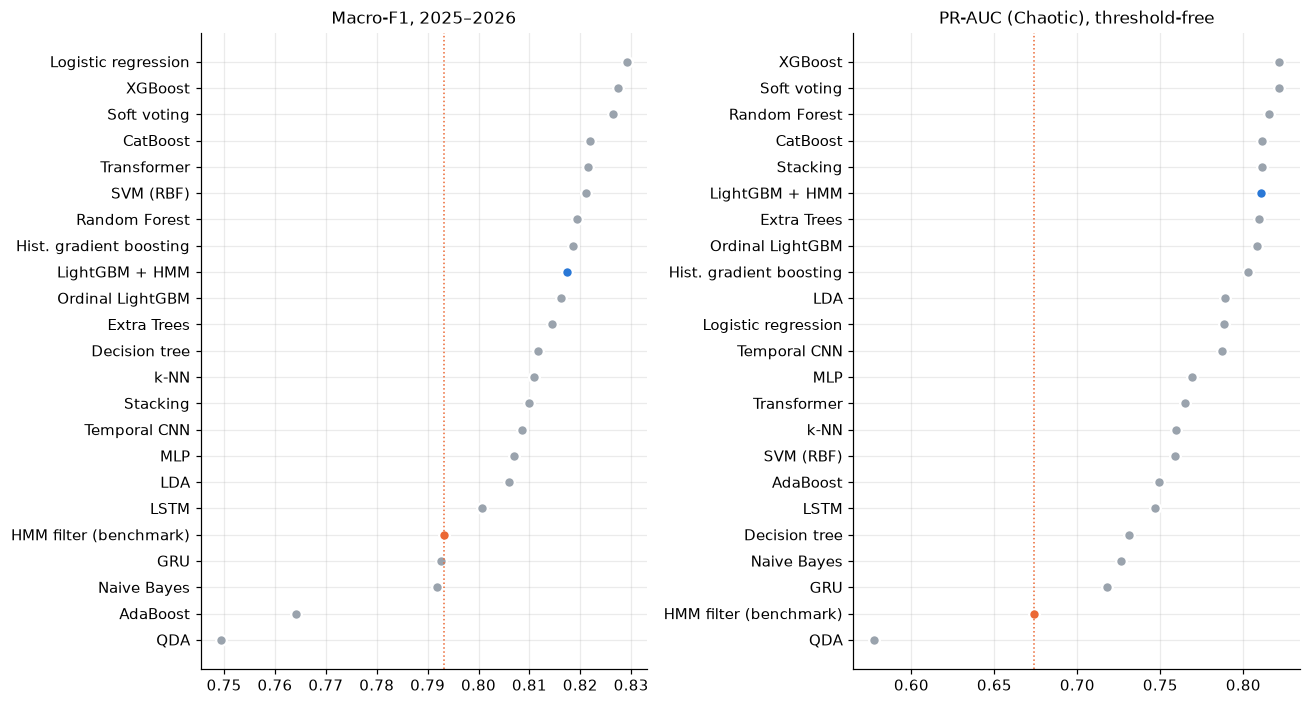

In [7]:
def dot_plot(ax, values, title, lo=None, hi=None, ref=None):
    """Cleveland dot plot (a zoomed axis is fine for dots, not for bars). Production and benchmark highlighted."""
    order = values.sort_values().index
    for i, k in enumerate(order):
        c = HIGHLIGHT['production'] if k == PRODUCTION else HIGHLIGHT['benchmark'] if k == BENCHMARK else GREY
        if lo is not None:
            ax.plot([lo[k], hi[k]], [i, i], color=c, lw=2, solid_capstyle='round')
        ax.plot(values[k], i, 'o', color=c, ms=7, mec='white', mew=1.5)
    ax.set_yticks(range(len(order)), [names[k] for k in order])
    if ref is not None:
        ax.axvline(ref, color=HIGHLIGHT['benchmark'], lw=1, ls=':')
    ax.set_title(title)


names = {k: v[0] for k, v in MODELS.items()} | {BENCHMARK: 'HMM filter (benchmark)'}
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
dot_plot(axes[0], holdout['macro_f1'].astype(float), 'Macro-F1, 2025–2026', ref=holdout.loc[BENCHMARK, 'macro_f1'])
dot_plot(axes[1], holdout['pr_auc_chaotic'].astype(float), 'PR-AUC (Chaotic), threshold-free',
         ref=holdout.loc[BENCHMARK, 'pr_auc_chaotic'])
axes[1].set_yticklabels([names[k] for k in holdout['pr_auc_chaotic'].astype(float).sort_values().index])
fig.tight_layout(); fig.savefig(FIG / 'zoo_holdout_scores.png', dpi=130); plt.show()

### Detection vs false alarms

For an alerting system the useful trade-off is how many Chaotic bars are caught against how many false alarms
per week it costs. Models toward the top left are better.

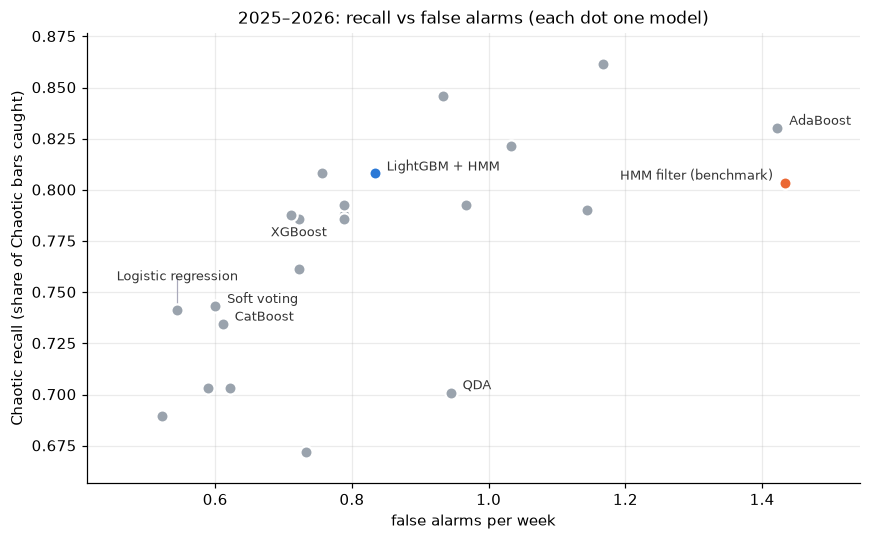

In [8]:
h = holdout.astype({'chaotic_recall': float, 'false_alarms_per_week': float, 'macro_f1': float})
fig, ax = plt.subplots(figsize=(8, 5))
for k, r in h.iterrows():
    c = HIGHLIGHT['production'] if k == PRODUCTION else HIGHLIGHT['benchmark'] if k == BENCHMARK else GREY
    ax.plot(r['false_alarms_per_week'], r['chaotic_recall'], 'o', color=c, ms=8, mec='white', mew=1.5)
label = set(h['macro_f1'].nlargest(4).index) | {PRODUCTION, BENCHMARK} | set(h['macro_f1'].nsmallest(2).index)
ax.set_xlabel('false alarms per week'); ax.set_ylabel('Chaotic recall (share of Chaotic bars caught)')
ax.set_title('2025–2026: recall vs false alarms (each dot one model)')
ax.margins(x=0.12, y=0.08)   # room for labels at the edges
fig.tight_layout()
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
to_px, to_data = ax.transData.transform, ax.transData.inverted().transform
taken = [to_px((r['false_alarms_per_week'], r['chaotic_recall'])) for _, r in h.iterrows()]
placed, ax_box, scale = [], ax.get_window_extent(), fig.dpi / 72
# candidate spots (in points) on rings around each labelled dot; far spots get a thin leader line
spots = [(r * np.cos(a), r * np.sin(a)) for r in (9, 22, 36, 52) for a in np.deg2rad([30, -30, 150, -150, 90, -90, 0, 180])]
for k in h.loc[list(label)].sort_values('false_alarms_per_week').index:
    xy = (h.loc[k, 'false_alarms_per_week'], h.loc[k, 'chaotic_recall'])
    here = to_px(xy)
    for dx, dy in spots:   # the first free spot inside the axes; the nearest one if none is free
        ha = 'left' if dx > 1 else 'right' if dx < -1 else 'center'
        pos = to_data(here + np.array([dx, dy]) * scale)
        t = ax.text(*pos, names[k], ha=ha, va='center', fontsize=8.5, color='#333')
        box = t.get_window_extent(renderer).expanded(1.05, 1.15)
        inside = ax_box.x0 <= box.x0 and box.x1 <= ax_box.x1 and ax_box.y0 <= box.y0 and box.y1 <= ax_box.y1
        free = not any(box.overlaps(o) for o in placed) and not any(
            box.padded(7).contains(*pt) for pt in taken if not np.allclose(pt, here))
        if inside and free:
            break
        t.remove()
    else:
        dx, dy = spots[0]
        pos = to_data(here + np.array([dx, dy]) * scale)
        t = ax.text(*pos, names[k], ha='left', va='center', fontsize=8.5, color='#333')
        box = t.get_window_extent(renderer)
    placed.append(box)
    if np.hypot(dx, dy) > 10:
        ax.plot([xy[0], pos[0]], [xy[1], pos[1]], color='#aab', lw=0.8, zorder=1)
fig.savefig(FIG / 'zoo_recall_vs_false_alarms.png', dpi=130); plt.show()

### Do the models make the same calls?

Pearson correlation of P(Chaotic) across models on the test bars, and how often their calls agree. High values mean
the zoo is mostly many routes to the same answer: the information is in the inputs, not in the choice of algorithm.
(Pearson, not rank correlation: on calm bars every model's P(Chaotic) is near zero, and the order of those tiny
values is noise that would dominate a rank correlation.)

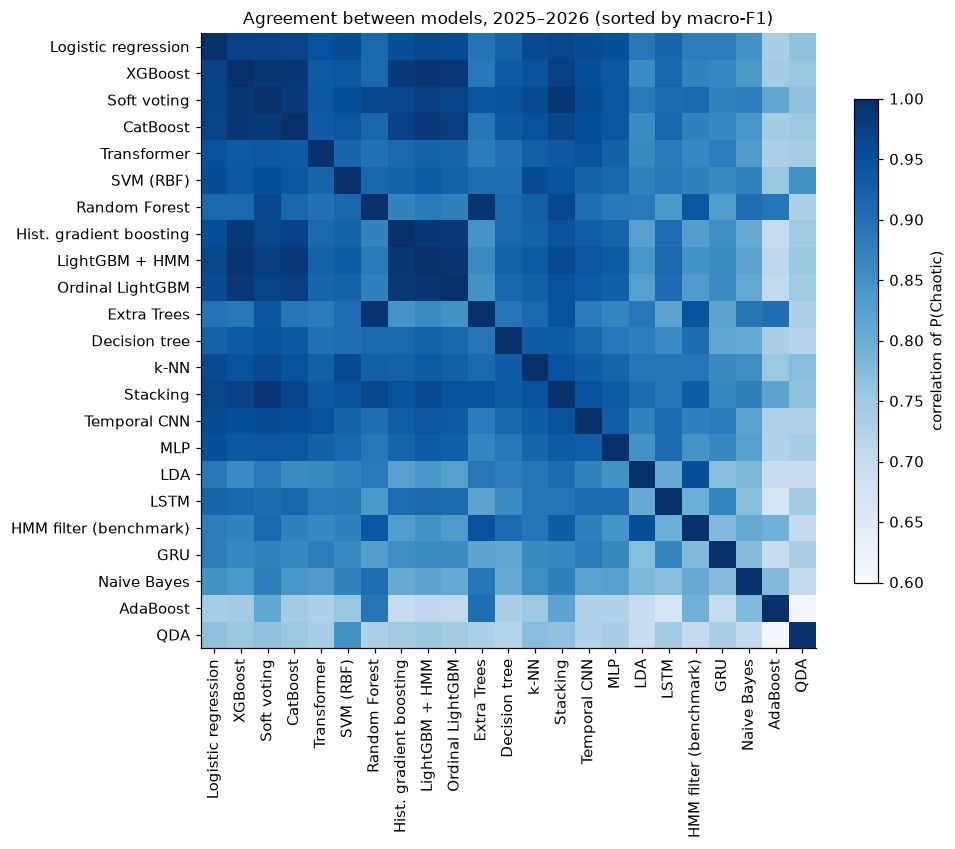

median pairwise correlation 0.89, lowest 0.61 (AdaBoost vs QDA); two models make the same Chaotic / not-Chaotic call (at P = 0.5) on 98.1% of bars (median pair)


In [9]:
P = pd.DataFrame(probas)
order = holdout['macro_f1'].astype(float).sort_values(ascending=False).index.intersection(P.columns)
corr = P[order].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='Blues', vmin=0.6, vmax=1)
ax.set_xticks(range(len(order)), [names[k] for k in order], rotation=90)
ax.set_yticks(range(len(order)), [names[k] for k in order])
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label='correlation of P(Chaotic)')
ax.set_title('Agreement between models, 2025–2026 (sorted by macro-F1)')
fig.tight_layout(); fig.savefig(FIG / 'zoo_agreement.png', dpi=130); plt.show()
off = corr.where(~np.eye(len(corr), dtype=bool)).stack()
calls = P >= 0.5
same = pd.DataFrame({a: {b: (calls[a] == calls[b]).mean() for b in order} for a in order})
same_off = same.where(~np.eye(len(same), dtype=bool)).stack()
print(f'median pairwise correlation {off.median():.2f}, lowest {off.min():.2f} ({" vs ".join(names[k] for k in off.idxmin())}); '
      f'two models make the same Chaotic / not-Chaotic call (at P = 0.5) on {same_off.median():.1%} of bars (median pair)')

### Case study: 7 April 2025

P(Chaotic) bar by bar for a few representative models from different families, on the session of the US tariff
shock and the sessions around it.

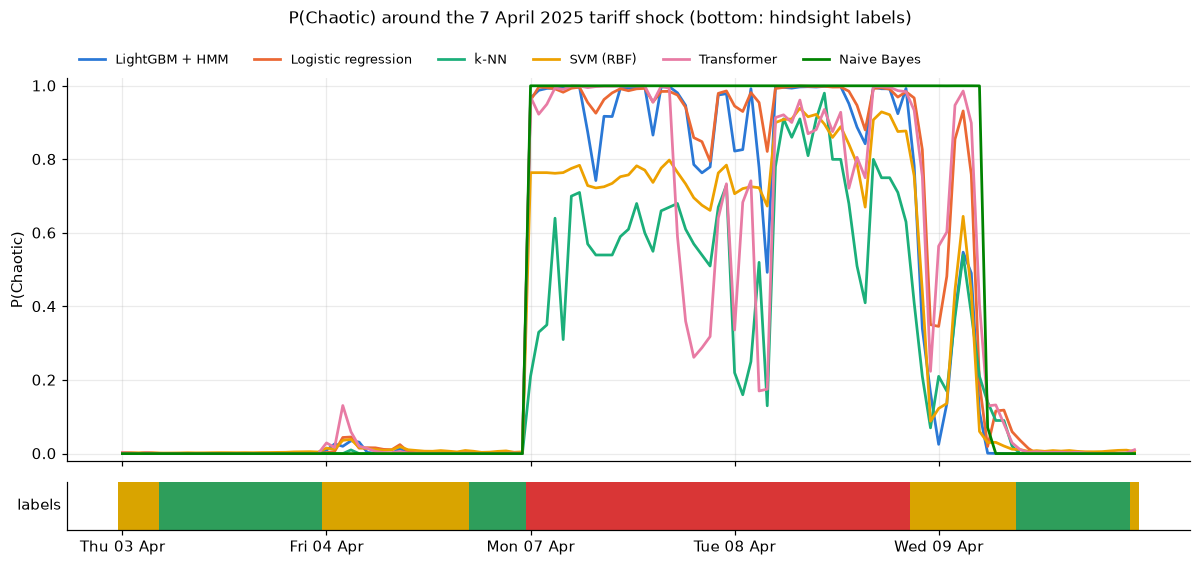

In [10]:
show = [PRODUCTION, 'logistic', 'knn', 'svm', 'transformer', 'naive_bayes']
win = P.loc['2025-04-03':'2025-04-09'].index
x = np.arange(len(win))
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, gridspec_kw={'height_ratios': [4, 0.5]})
palette = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']   # categorical slots, fixed order
for k, c in zip(show, palette):
    axes[0].plot(x, P.loc[win, k], color=c, lw=1.8, label=names[k])
axes[0].set_ylabel('P(Chaotic)'); axes[0].set_ylim(-0.02, 1.02)
axes[0].legend(frameon=False, ncol=6, loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=8.5)
for t, r in enumerate(y.reindex(win).to_numpy()):
    axes[1].axvspan(t - 0.5, t + 0.5, color=REGIME_COLORS[int(r)], lw=0)
axes[1].set_yticks([]); axes[1].grid(False); axes[1].set_ylabel('labels', rotation=0, ha='right', va='center')
starts = [i for i in range(len(win)) if i == 0 or win[i].date() != win[i - 1].date()]
axes[1].set_xticks(starts, [win[i].strftime('%a %d %b') for i in starts])
fig.suptitle('P(Chaotic) around the 7 April 2025 tariff shock (bottom: hindsight labels)')
fig.tight_layout(); fig.savefig(FIG / 'zoo_case_2025_04_07.png', dpi=130); plt.show()

# Part B: walk-forward evaluation 2022–2026

The main evaluation (`scripts/train_zoo.py`): each test year is predicted by a model trained only on the years before
it (expanding window from 2017), with τ tuned on the last training year. Out-of-sample predictions for every model are
in `data/processed/zoo/`.

In [11]:
wf = pd.read_csv(OUT / 'zoo_results.csv', index_col='key')
preds = {k: pd.read_parquet(OUT / 'zoo' / f'{k}_wf.parquet')['pred'] for k in wf.index if k != BENCHMARK}
idx = preds[PRODUCTION].index
yy = hmm.hindsight(model_frame(load_raw(), hmm)).reindex(idx)
xx = model_frame(load_raw(), hmm).loc[idx]
preds[BENCHMARK] = pd.Series(xx[['p_hmm_Quiet', 'p_hmm_Normal', 'p_hmm_Chaotic']].to_numpy().argmax(1), index=idx)
wf[['model', 'family', 'macro_f1', 'chaotic_precision', 'chaotic_recall', 'episode_recall', 'false_alarms_per_week']].round(3)

,model,family,macro_f1,chaotic_precision,chaotic_recall,episode_recall,false_alarms_per_week
key,,,,,,,
soft_vote,Soft voting,Ensemble,0.840,0.714,0.778,1.000,0.586
xgboost,XGBoost,Gradient boosting,0.838,0.750,0.729,0.985,0.539
logistic,Logistic regression,Linear,0.836,0.743,0.731,0.963,0.586
catboost,CatBoost,Gradient boosting,0.835,0.701,0.775,0.993,0.708
random_forest,Random Forest,Bagging,0.833,0.688,0.782,1.000,0.666
svm,SVM (RBF),Kernel method,0.831,0.692,0.762,0.978,0.687
extra_trees,Extra Trees,Bagging,0.829,0.661,0.804,1.000,0.931
ordinal,Ordinal LightGBM,Ordinal,0.829,0.685,0.772,0.985,0.708
knn,k-NN,Instance-based,0.829,0.732,0.735,0.970,0.628


### Is the ranking real? Block bootstrap

The top of the leaderboard is separated by thousandths, so a ranking means little without uncertainty. Bars within a
week are strongly dependent, so the bootstrap resamples whole **weeks** (252 blocks) of out-of-sample predictions,
300 times, and recomputes macro-F1 for every model on the same resample. The interval on the *difference* to the
production model is the honest test.

In [12]:
yt = yy.to_numpy()
Pm = {k: v.reindex(idx).to_numpy() for k, v in preds.items()}
week = pd.factorize(idx.tz_localize(None).to_period('W'))[0]
blocks = [np.flatnonzero(week == w) for w in range(week.max() + 1)]
rng = np.random.default_rng(0)
boot = {k: [] for k in Pm}
for _ in range(300):
    r = np.concatenate([blocks[i] for i in rng.integers(0, len(blocks), len(blocks))])
    for k in Pm:
        boot[k].append(f1_score(yt[r], Pm[k][r], average='macro'))
B = pd.DataFrame(boot)
D = B.sub(B[PRODUCTION], axis=0)
ci = pd.DataFrame({'macro_f1': {k: f1_score(yt, Pm[k], average='macro') for k in Pm},
                   'low': B.quantile(0.025), 'high': B.quantile(0.975),
                   'diff_vs_production': D.mean(), 'diff_low': D.quantile(0.025), 'diff_high': D.quantile(0.975)})
ci['verdict'] = np.where(ci.diff_low > 0, 'better', np.where(ci.diff_high < 0, 'worse', 'no difference'))
ci.loc[PRODUCTION, 'verdict'] = 'production'
ci.insert(0, 'model', [names[k] for k in ci.index])
ci = ci.sort_values('macro_f1', ascending=False)
ci.to_csv(OUT / 'zoo_bootstrap.csv')
ci.round(3)

,model,macro_f1,low,high,diff_vs_production,diff_low,diff_high,verdict
soft_vote,Soft voting,0.840,0.823,0.851,0.012,0.005,0.018,better
xgboost,XGBoost,0.838,0.820,0.850,0.009,0.004,0.015,better
logistic,Logistic regression,0.836,0.822,0.846,0.008,-0.001,0.017,no difference
catboost,CatBoost,0.835,0.819,0.845,0.006,-0.001,0.014,no difference
random_forest,Random Forest,0.833,0.817,0.845,0.005,-0.002,0.013,no difference
svm,SVM (RBF),0.831,0.816,0.841,0.003,-0.006,0.011,no difference
extra_trees,Extra Trees,0.829,0.814,0.841,0.001,-0.008,0.009,no difference
ordinal,Ordinal LightGBM,0.829,0.812,0.842,0.001,-0.006,0.008,no difference
knn,k-NN,0.829,0.813,0.840,0.001,-0.010,0.010,no difference
lightgbm,LightGBM + HMM,0.829,0.809,0.842,0.000,0.000,0.000,production


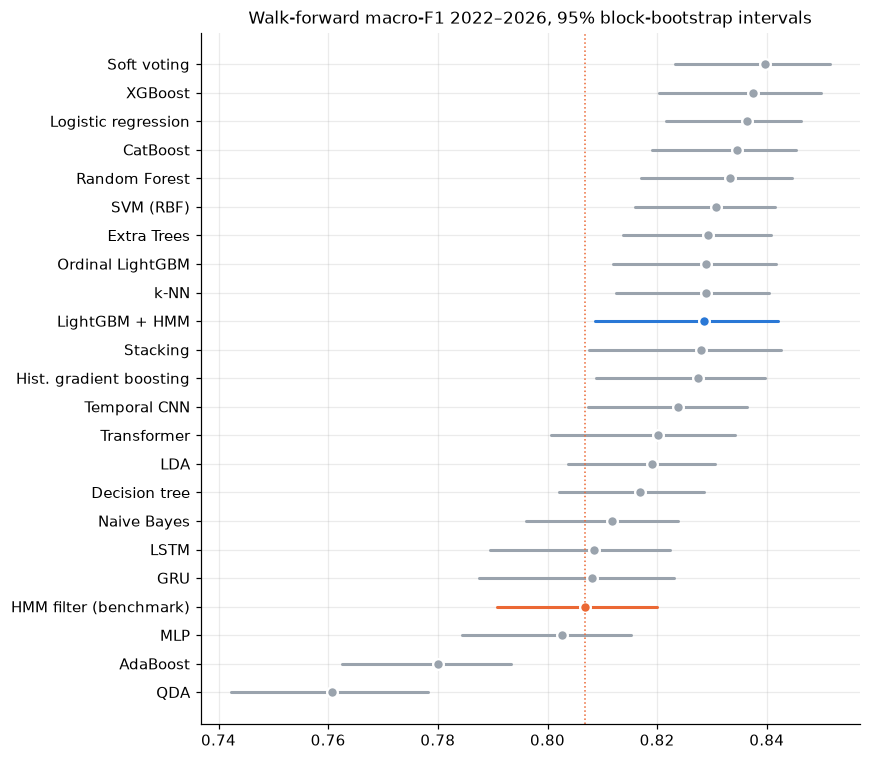

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
dot_plot(ax, ci['macro_f1'], 'Walk-forward macro-F1 2022–2026, 95% block-bootstrap intervals',
         lo=ci['low'], hi=ci['high'], ref=ci.loc[BENCHMARK, 'macro_f1'])
fig.tight_layout(); fig.savefig(FIG / 'zoo_walkforward_ci.png', dpi=130); plt.show()

### Year by year

Macro-F1 per test year. A model that wins overall but loses in most years is not a robust winner.

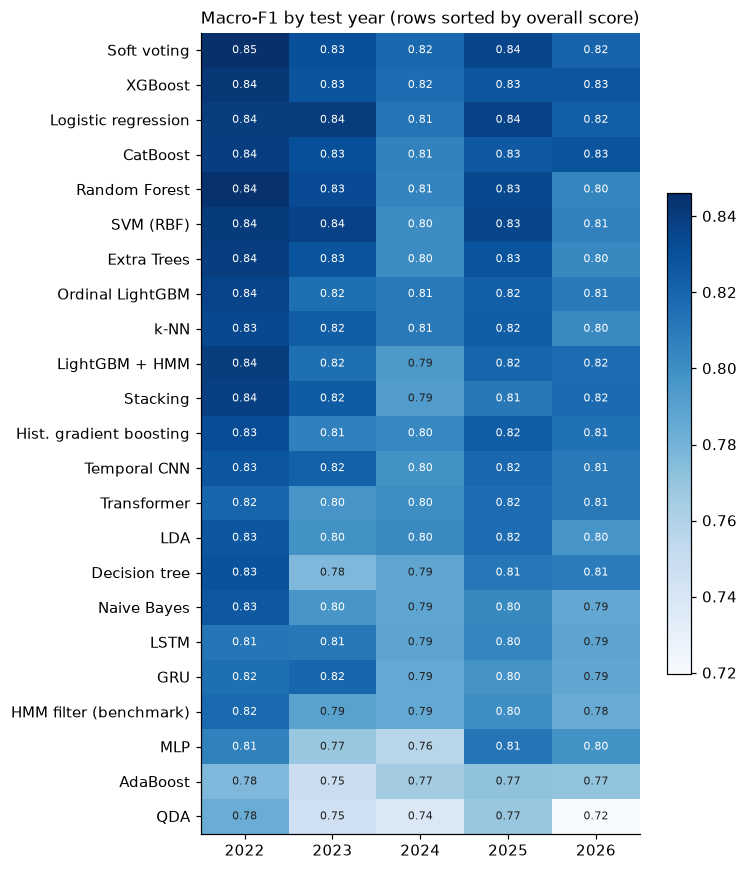

rank of production model by year: {2022: 6, 2023: 12, 2024: 14, 2025: 11, 2026: 6}


In [14]:
years = sorted(set(idx.year))
by_year = pd.DataFrame({k: {yr: f1_score(yt[idx.year == yr], Pm[k][idx.year == yr], average='macro') for yr in years}
                        for k in Pm}).T
by_year = by_year.loc[ci.index]
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(by_year.to_numpy(), cmap='Blues', aspect='auto', vmin=by_year.min().min(), vmax=by_year.max().max())
ax.set_xticks(range(len(years)), years); ax.set_yticks(range(len(by_year)), [names[k] for k in by_year.index])
for i in range(by_year.shape[0]):
    for j in range(by_year.shape[1]):
        v = by_year.iat[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5,
                color='white' if v > by_year.min().min() + 0.6 * (by_year.max().max() - by_year.min().min()) else '#222')
ax.grid(False); ax.set_title('Macro-F1 by test year (rows sorted by overall score)')
fig.colorbar(im, ax=ax, shrink=0.6)
fig.tight_layout(); fig.savefig(FIG / 'zoo_by_year.png', dpi=130); plt.show()
print('rank of production model by year:', by_year.rank(ascending=False).loc[PRODUCTION].astype(int).to_dict())

## Takeaways

* **A single split is not enough to rank models.** On 2025–2026 alone (45 Chaotic episodes) logistic regression
  tops macro-F1 (0.829) and production LightGBM is 9th (0.817), mostly because 2024 happened to tune its τ to 0.15
  (0.83 false alarms/week). On threshold-free PR-AUC the order changes again (XGBoost 0.822, soft voting 0.821,
  LightGBM 0.810). Rankings at the top depend on the split and the metric.
* **Almost everything beats the HMM filter.** On 2025–2026 every model except QDA has a higher PR-AUC than the
  benchmark (0.674); 18 of 22 have a higher macro-F1.
* **The models largely agree.** Median correlation of P(Chaotic) between two models is 0.89, and two models make
  the same Chaotic / not-Chaotic call on 98% of bars. They differ mainly in confidence during an episode: on
  7 April 2025 all of them flag Chaotic on the first bar, k-NN and SVM are less sure mid-session, and naive Bayes
  is all-or-nothing (its independence assumption makes it overconfident).
* **Walk-forward with uncertainty (the result to report).** Over 2022–2026 only soft voting (+0.012 macro-F1,
  95% interval [+0.005, +0.018]) and XGBoost (+0.009, [+0.004, +0.015]) are significantly better than production
  LightGBM. Eleven models are statistically tied with it. Decision tree, naive Bayes, LSTM, GRU, MLP, AdaBoost,
  QDA and the HMM filter are significantly worse. Production beats the benchmark by +0.022 [+0.011, +0.033].
* **Year by year,** production ranks between 6th and 14th of 23 on macro-F1, while soft voting, XGBoost and
  logistic regression stay near the top every year. 2024 is the hardest year for almost every model.
* **Why LightGBM stays in production:** it raises the fewest false alarms of any model (0.48 per week over
  2022–2026, vs 0.59 for soft voting and 1.45 for the HMM filter), which is what matters for an alerting system.
  Soft voting is the best-F1 alternative if a few more alarms are acceptable.
* **Sequence models do not help here.** The temporal CNN is the best of them (0.824) and still not better than
  per-bar models; LSTM and GRU are significantly worse. With ~230 Chaotic episodes of training data, extra
  capacity does not pay (see the learning curves).